# 05. Interpretabilidad SHAP y Análisis Exhaustivo de Errores (TF1 - CC209)

**Objetivo:**
1. Explicar global y localmente el comportamiento del modelo ganador mediante valores **SHAP** (`src/explainability.py`).
2. Auditar los **Falsos Negativos (`53`)** y **Falsos Positivos (`234`)** en el conjunto Test (`1,057` clientes), desagregando el desempeño por segmentos de negocio.
3. Documentar casos concretos separando **evidencia observada** de **hipótesis explicativas**, y formular las conclusiones y limitaciones finales.

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

from src.config import REPORTS_DIR, FIGURES_TF1_DIR

## 1. Interpretabilidad Global y Local con SHAP

> **Precaución metodológica:** Los valores SHAP miden la **atribución aditiva** de cada variable a la predicción del modelo frente a la distribución de referencia (`background` de `Train + Val`); **no demuestran causalidad**.

,Variable,Mean_Abs_SHAP,Mean_Signed_SHAP
0,tenure,0.07529,0.00365
1,ContractRiskTier,0.06557,-0.02566
2,InternetService_Fiber optic,0.03790,-0.00019
3,OnlineSecurity_No,0.03057,-0.00282
4,PaymentMethod_Electronic check,0.02189,-0.00508
5,PaperlessBilling_Yes,0.01943,-0.00563
6,TechSupport_No,0.01614,-0.00095
7,MultipleLines_No,0.01499,0.00042
8,HighRisk_Fiber_No_Support,0.01495,0.00051
9,AvgMonthlyCharge,0.01448,0.00151


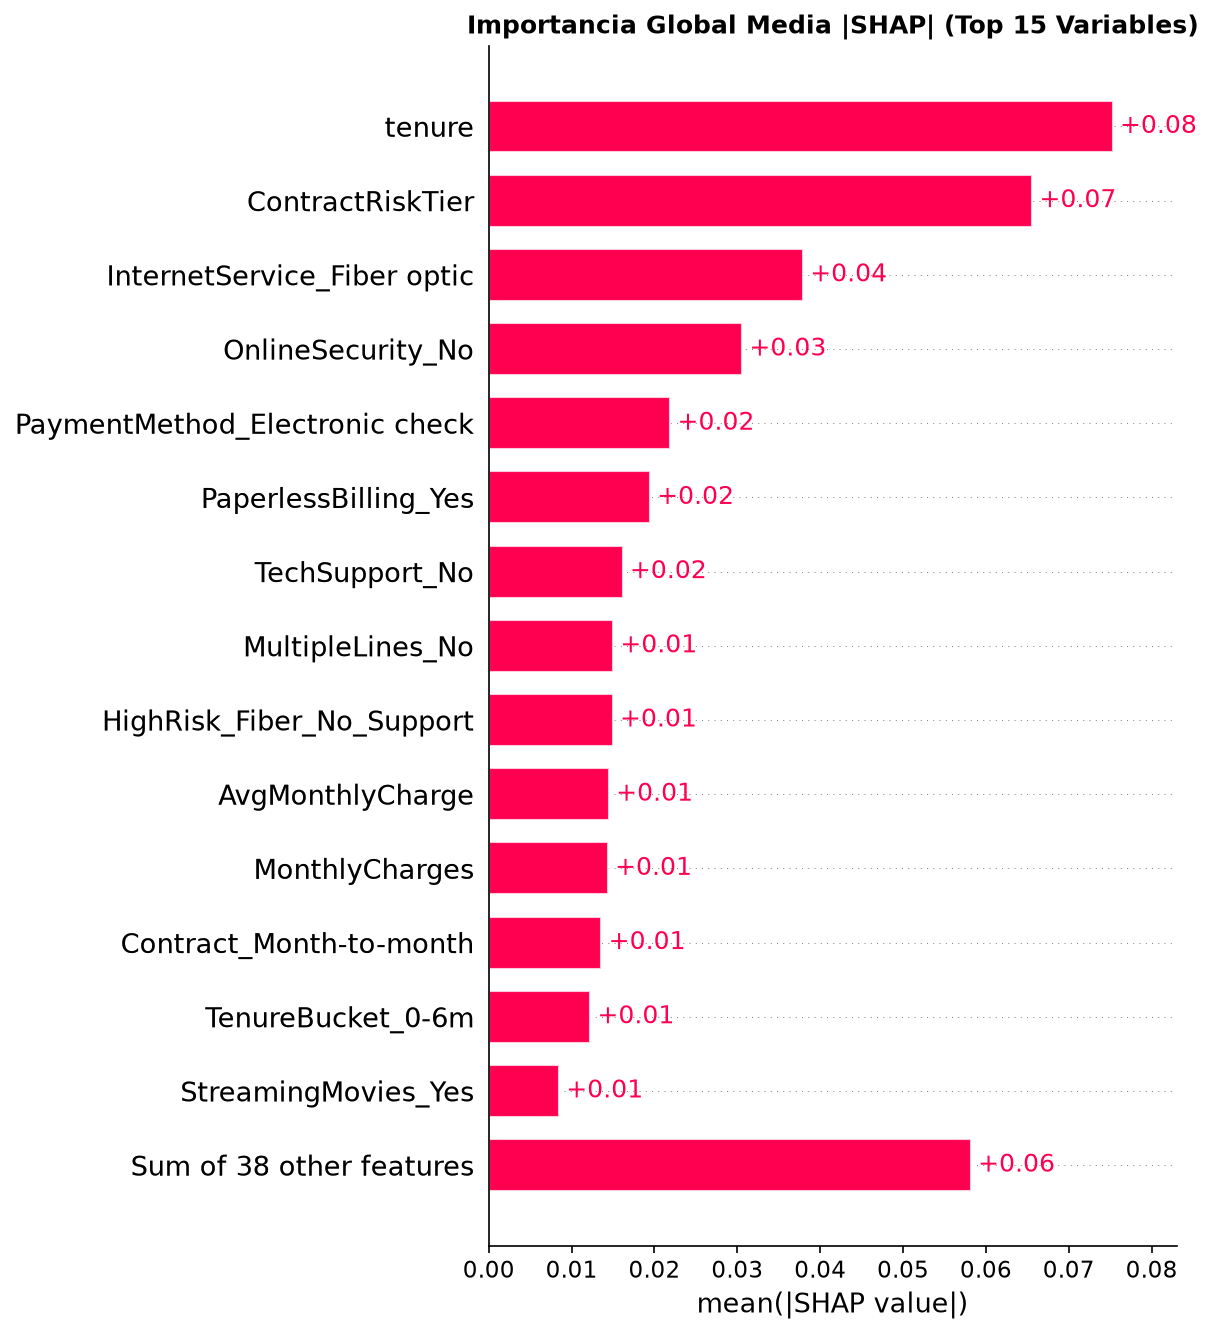

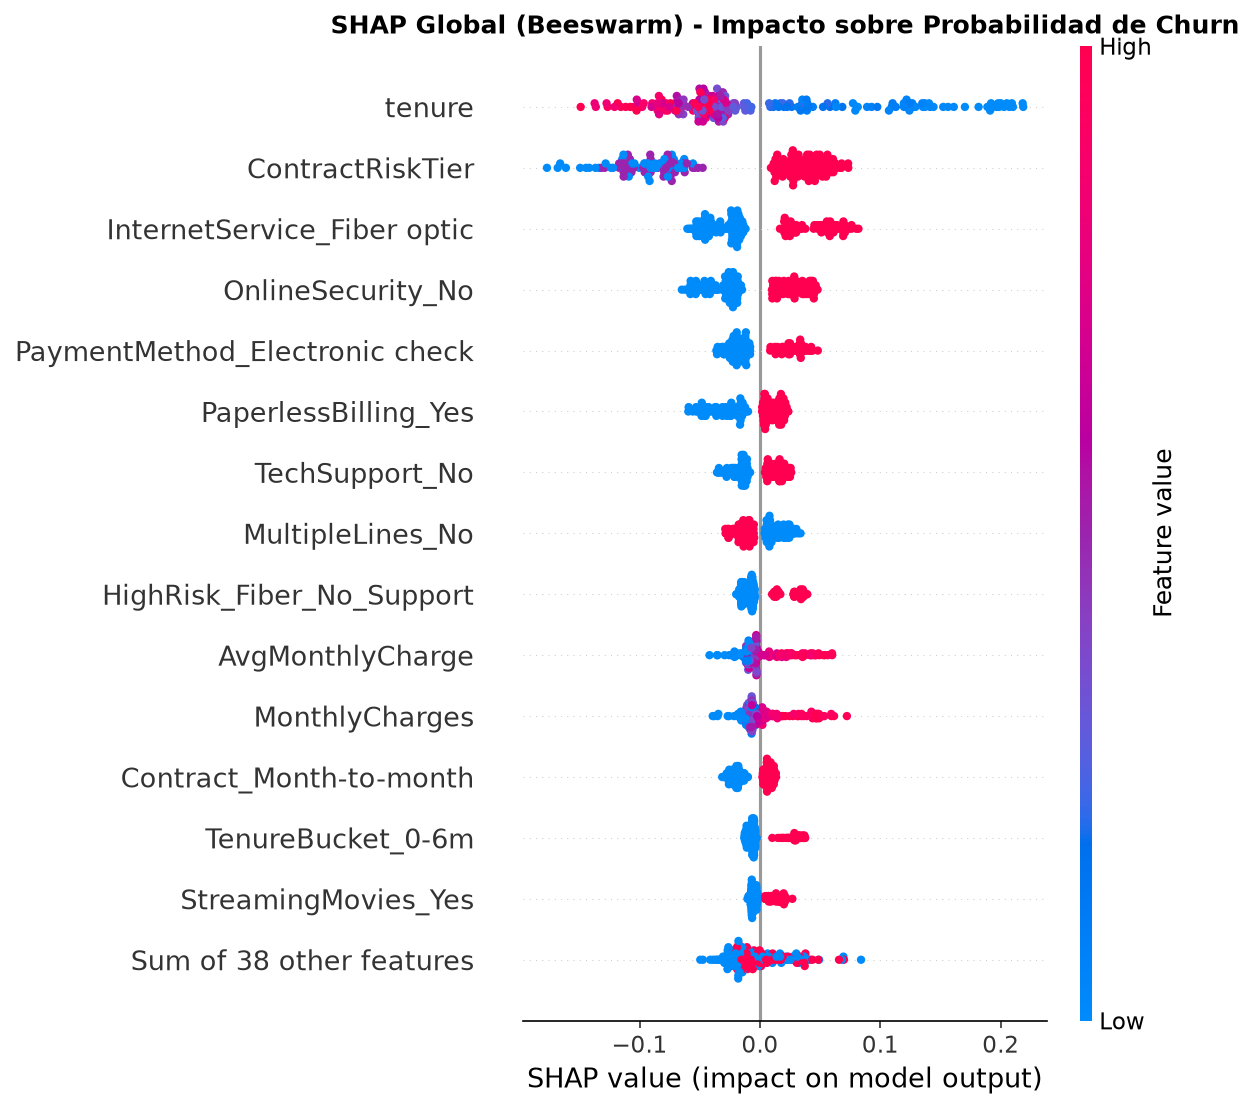

In [2]:
df_shap = pd.read_csv(REPORTS_DIR / "shap_importancia_global_tf1.csv")
display(df_shap.head(15).round(5))

display(Image(filename=str(FIGURES_TF1_DIR / "shap_global_bar.png")))
display(Image(filename=str(FIGURES_TF1_DIR / "shap_global_beeswarm.png")))

**Interpretación Global:**
- **Coherencia con el dominio y EDA:** Las variables con mayor impacto promedio son `tenure` (`0.0753`), `ContractRiskTier` (`0.0656`, variable de ingeniería TF1), `InternetService_Fiber optic` (`0.0379`), `OnlineSecurity_No` (`0.0306`), `PaymentMethod_Electronic check` (`0.0219`), `TechSupport_No` (`0.0161`) y `HighRisk_Fiber_No_Support` (`0.0149`).
- **Dirección de los efectos (Beeswarm):** Valores bajos de antigüedad (`tenure`), contratos de corto plazo (`ContractRiskTier = 2`), uso de fibra óptica sin seguridad/soporte y pago por cheque electrónico empujan positivamente la probabilidad de fuga.

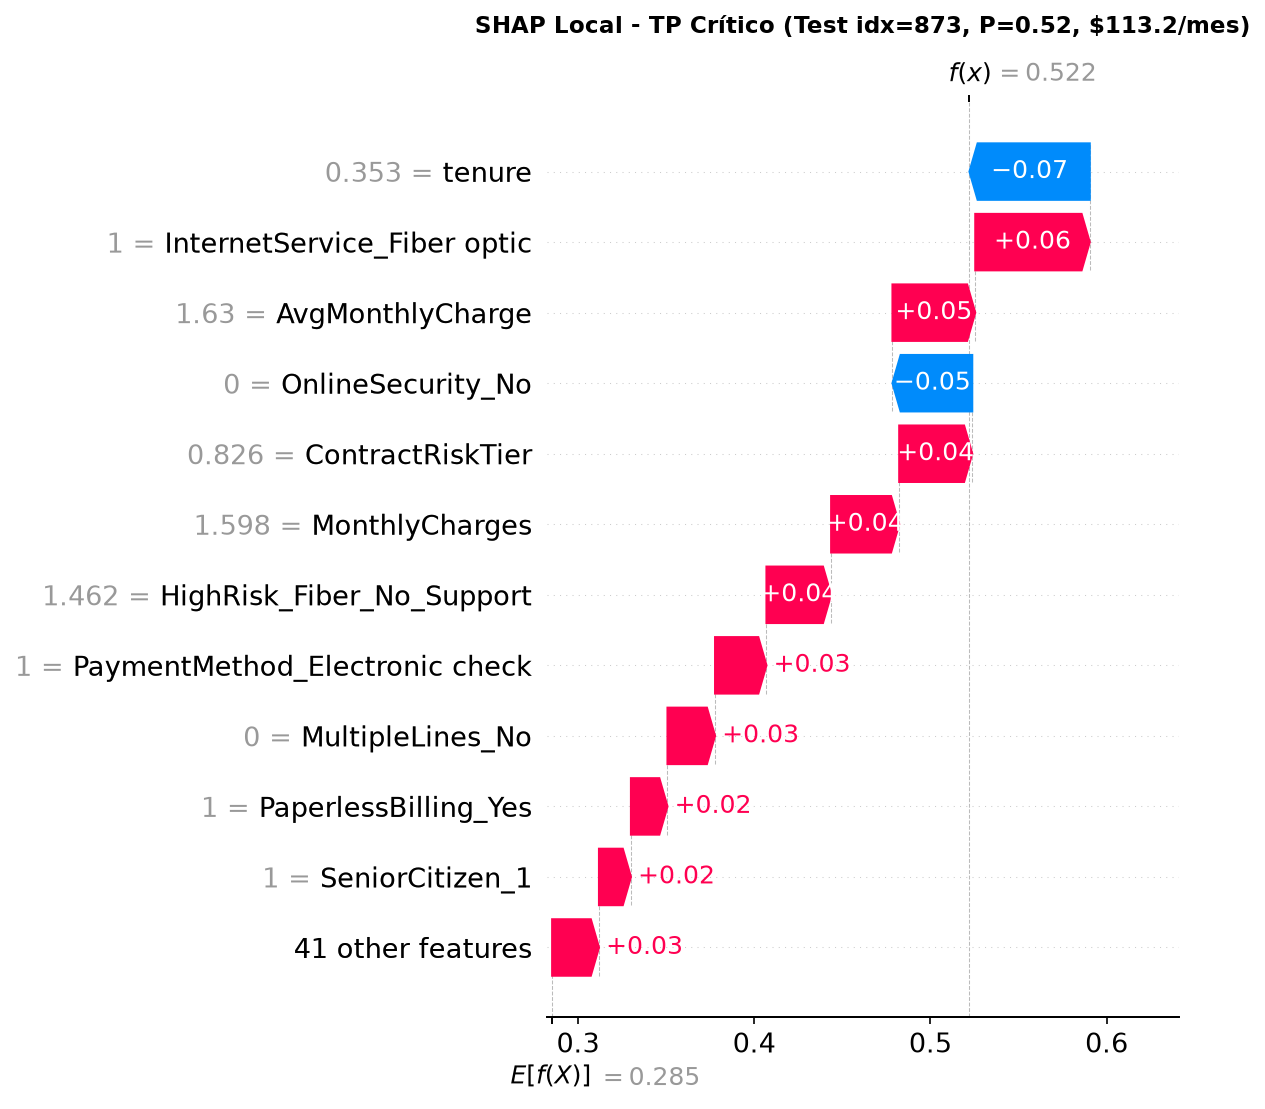

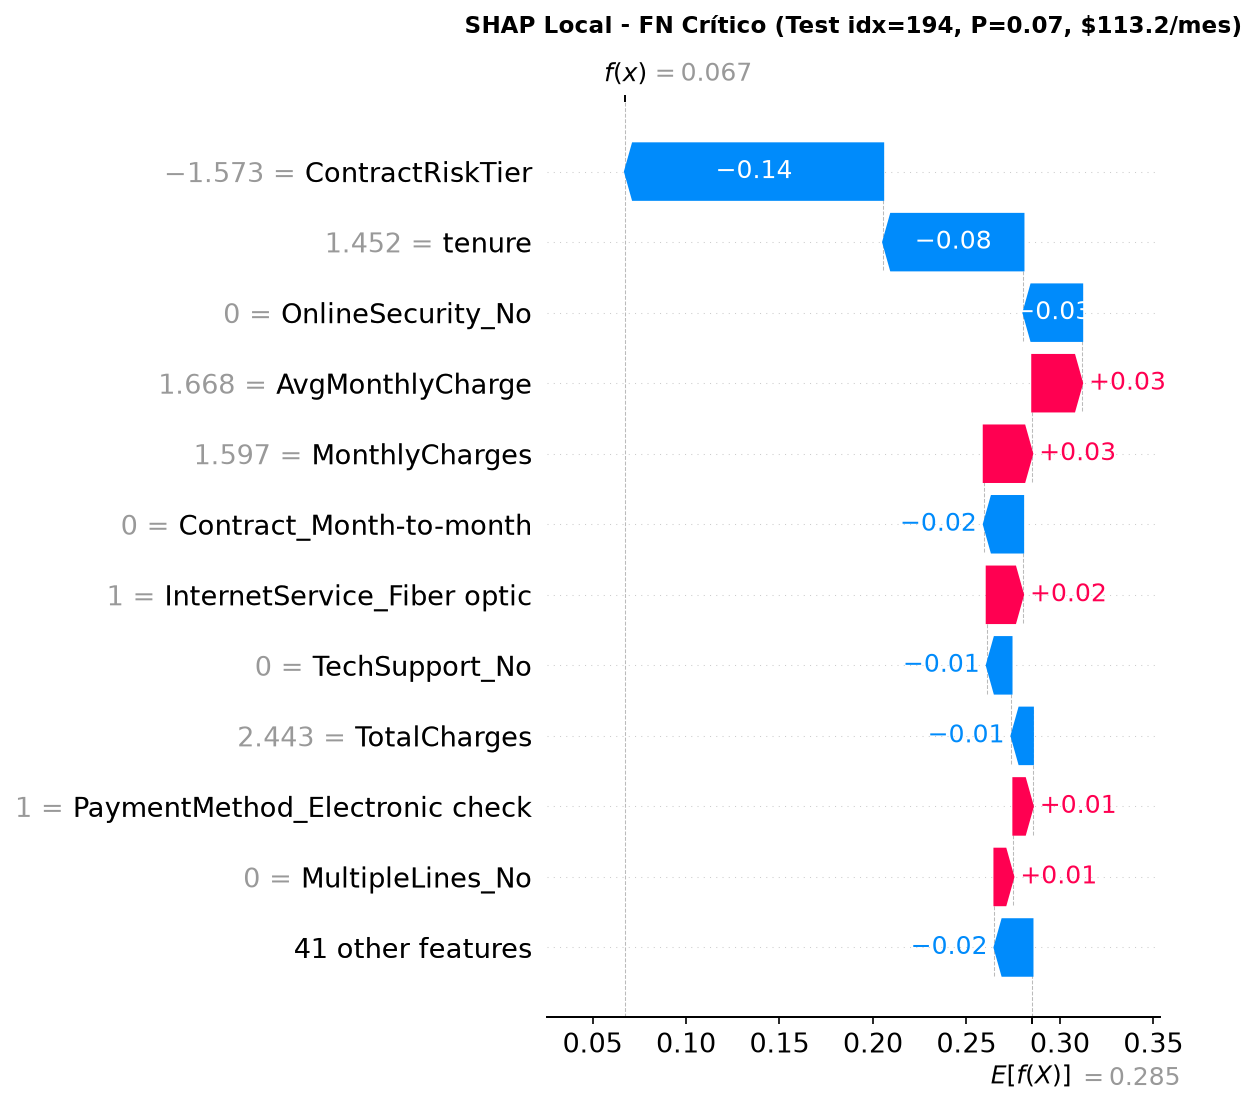

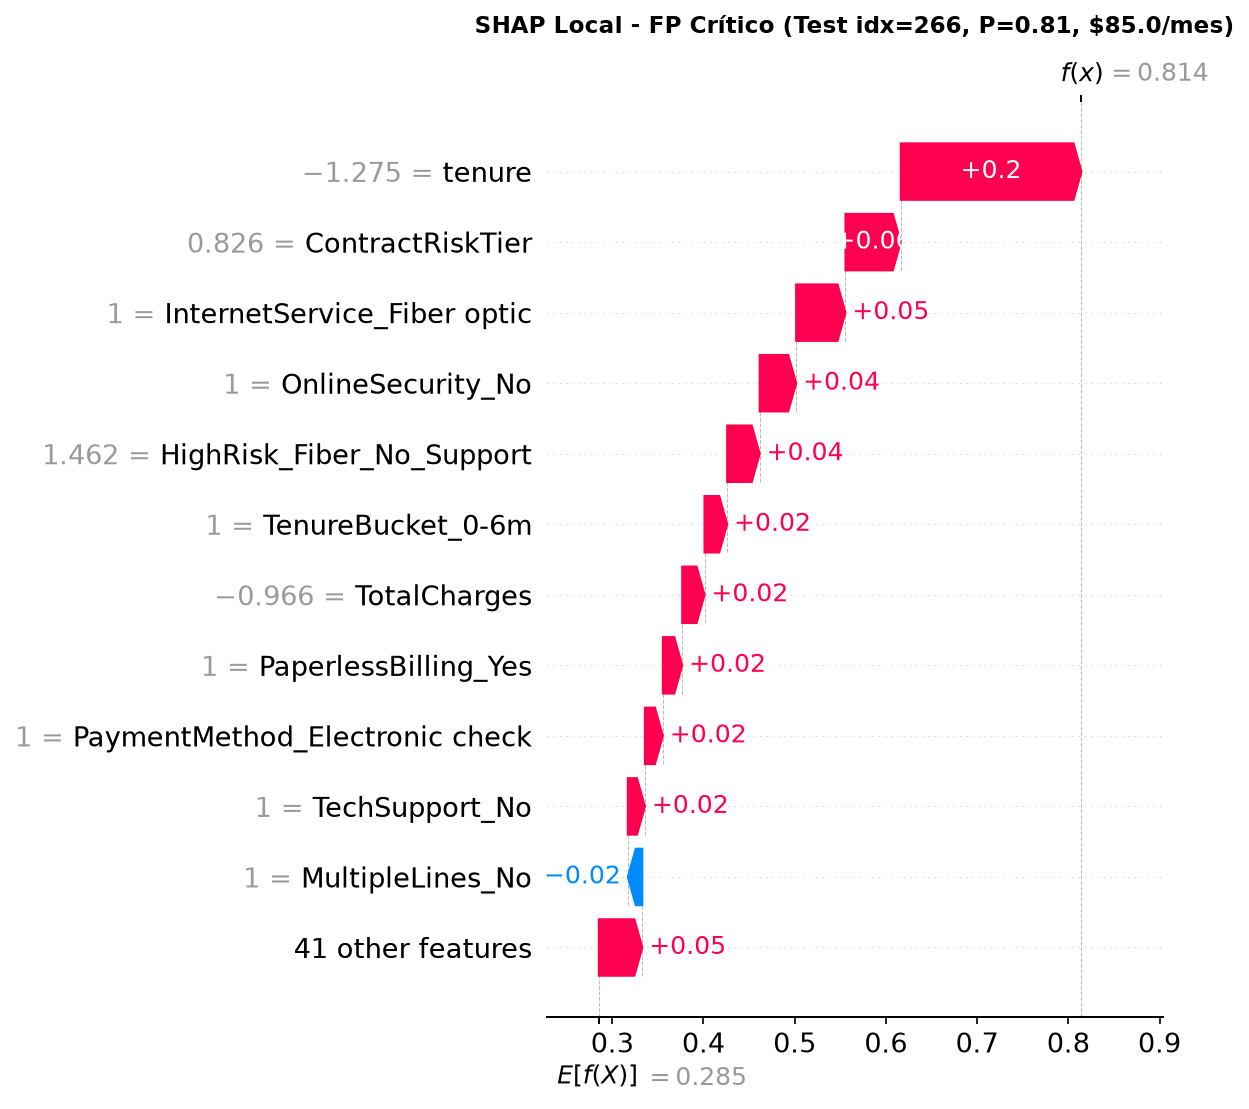

In [3]:
display(Image(filename=str(FIGURES_TF1_DIR / "shap_local_tp_critico.png")))
display(Image(filename=str(FIGURES_TF1_DIR / "shap_local_fn_critico.png")))
display(Image(filename=str(FIGURES_TF1_DIR / "shap_local_fp_critico.png")))

**Interpretación Local:**
- **TP Crítico:** El Waterfall muestra de forma accionable al asesor por qué el cliente recibió probabilidad alta (combinación de contrato mensual, fibra óptica, falta de soporte y baja antigüedad), orientando la oferta de retención (p. ej., bonificar soporte técnico o migrar a contrato anual).
- **FN Crítico:** Evidencia cómo la antigüedad elevada y contratos de plazo largo empujan la probabilidad estimada por debajo del umbral `0.20` pese a que el cliente terminó fugándose.
- **FP Crítico:** Muestra un cliente que cumple todas las señales estadísticas de riesgo pero permaneció retenido.

## 2. Auditoría de Errores (FN / FP) por Segmentos y Casos Concretos

,Resultado,Casos,Prob_Media,Tenure_Medio,MonthlyCharges_Medio,Servicios_Medios,Pct_Mes_a_Mes,Pct_Fibra,Pct_Sin_Soporte,Pct_Cheque_Elec
0,FN,53,0.1107,31.0189,59.9736,3.7736,0.4151,0.3019,0.4340,0.2830
1,FP,234,0.4173,21.9359,72.7013,3.6709,0.9145,0.6325,0.7265,0.5043
2,TN,542,0.0707,45.2362,54.9912,3.7030,0.2122,0.2030,0.2768,0.1273
3,TP,228,0.5602,14.0132,73.8757,3.3377,0.9693,0.7325,0.8553,0.6447


,Dimension,Segmento,N,Churn_Real_Rate,TP,FP,FN,TN,Recall,Value_Weighted_Recall,Precision,F1_Score,PR_AUC,MonthlyCharges_FN_Perdido
0,Contract,Month-to-month,572,0.4248,221,214,22,115,0.9095,0.9575,0.5080,0.6519,0.7117,715.85
1,Contract,One year,229,0.1441,7,20,26,176,0.2121,0.2658,0.2593,0.2333,0.2819,1999.85
2,Contract,Two year,256,0.0195,0,0,5,251,0.0000,0.0000,0.0000,0.0000,0.0960,462.90
3,TenureBucket,0-6m,229,0.5415,113,76,11,29,0.9113,0.9615,0.5979,0.7220,0.8285,288.05
4,TenureBucket,13-24m,157,0.3439,46,48,8,55,0.8519,0.8890,0.4894,0.6216,0.5821,440.90
5,TenureBucket,25-48m,230,0.2304,39,42,14,135,0.7358,0.7847,0.4815,0.5821,0.5202,980.65
6,TenureBucket,49m+,348,0.0747,12,38,14,284,0.4615,0.4757,0.2400,0.3158,0.3436,1247.60
7,TenureBucket,7-12m,93,0.2581,18,30,6,39,0.7500,0.8642,0.3750,0.5000,0.5283,221.40
8,InternetService,DSL,377,0.1963,52,67,22,236,0.7027,0.6324,0.4370,0.5389,0.6049,1319.05
9,InternetService,Fiber optic,441,0.4150,167,148,16,110,0.9126,0.9019,0.5302,0.6707,0.7354,1564.85


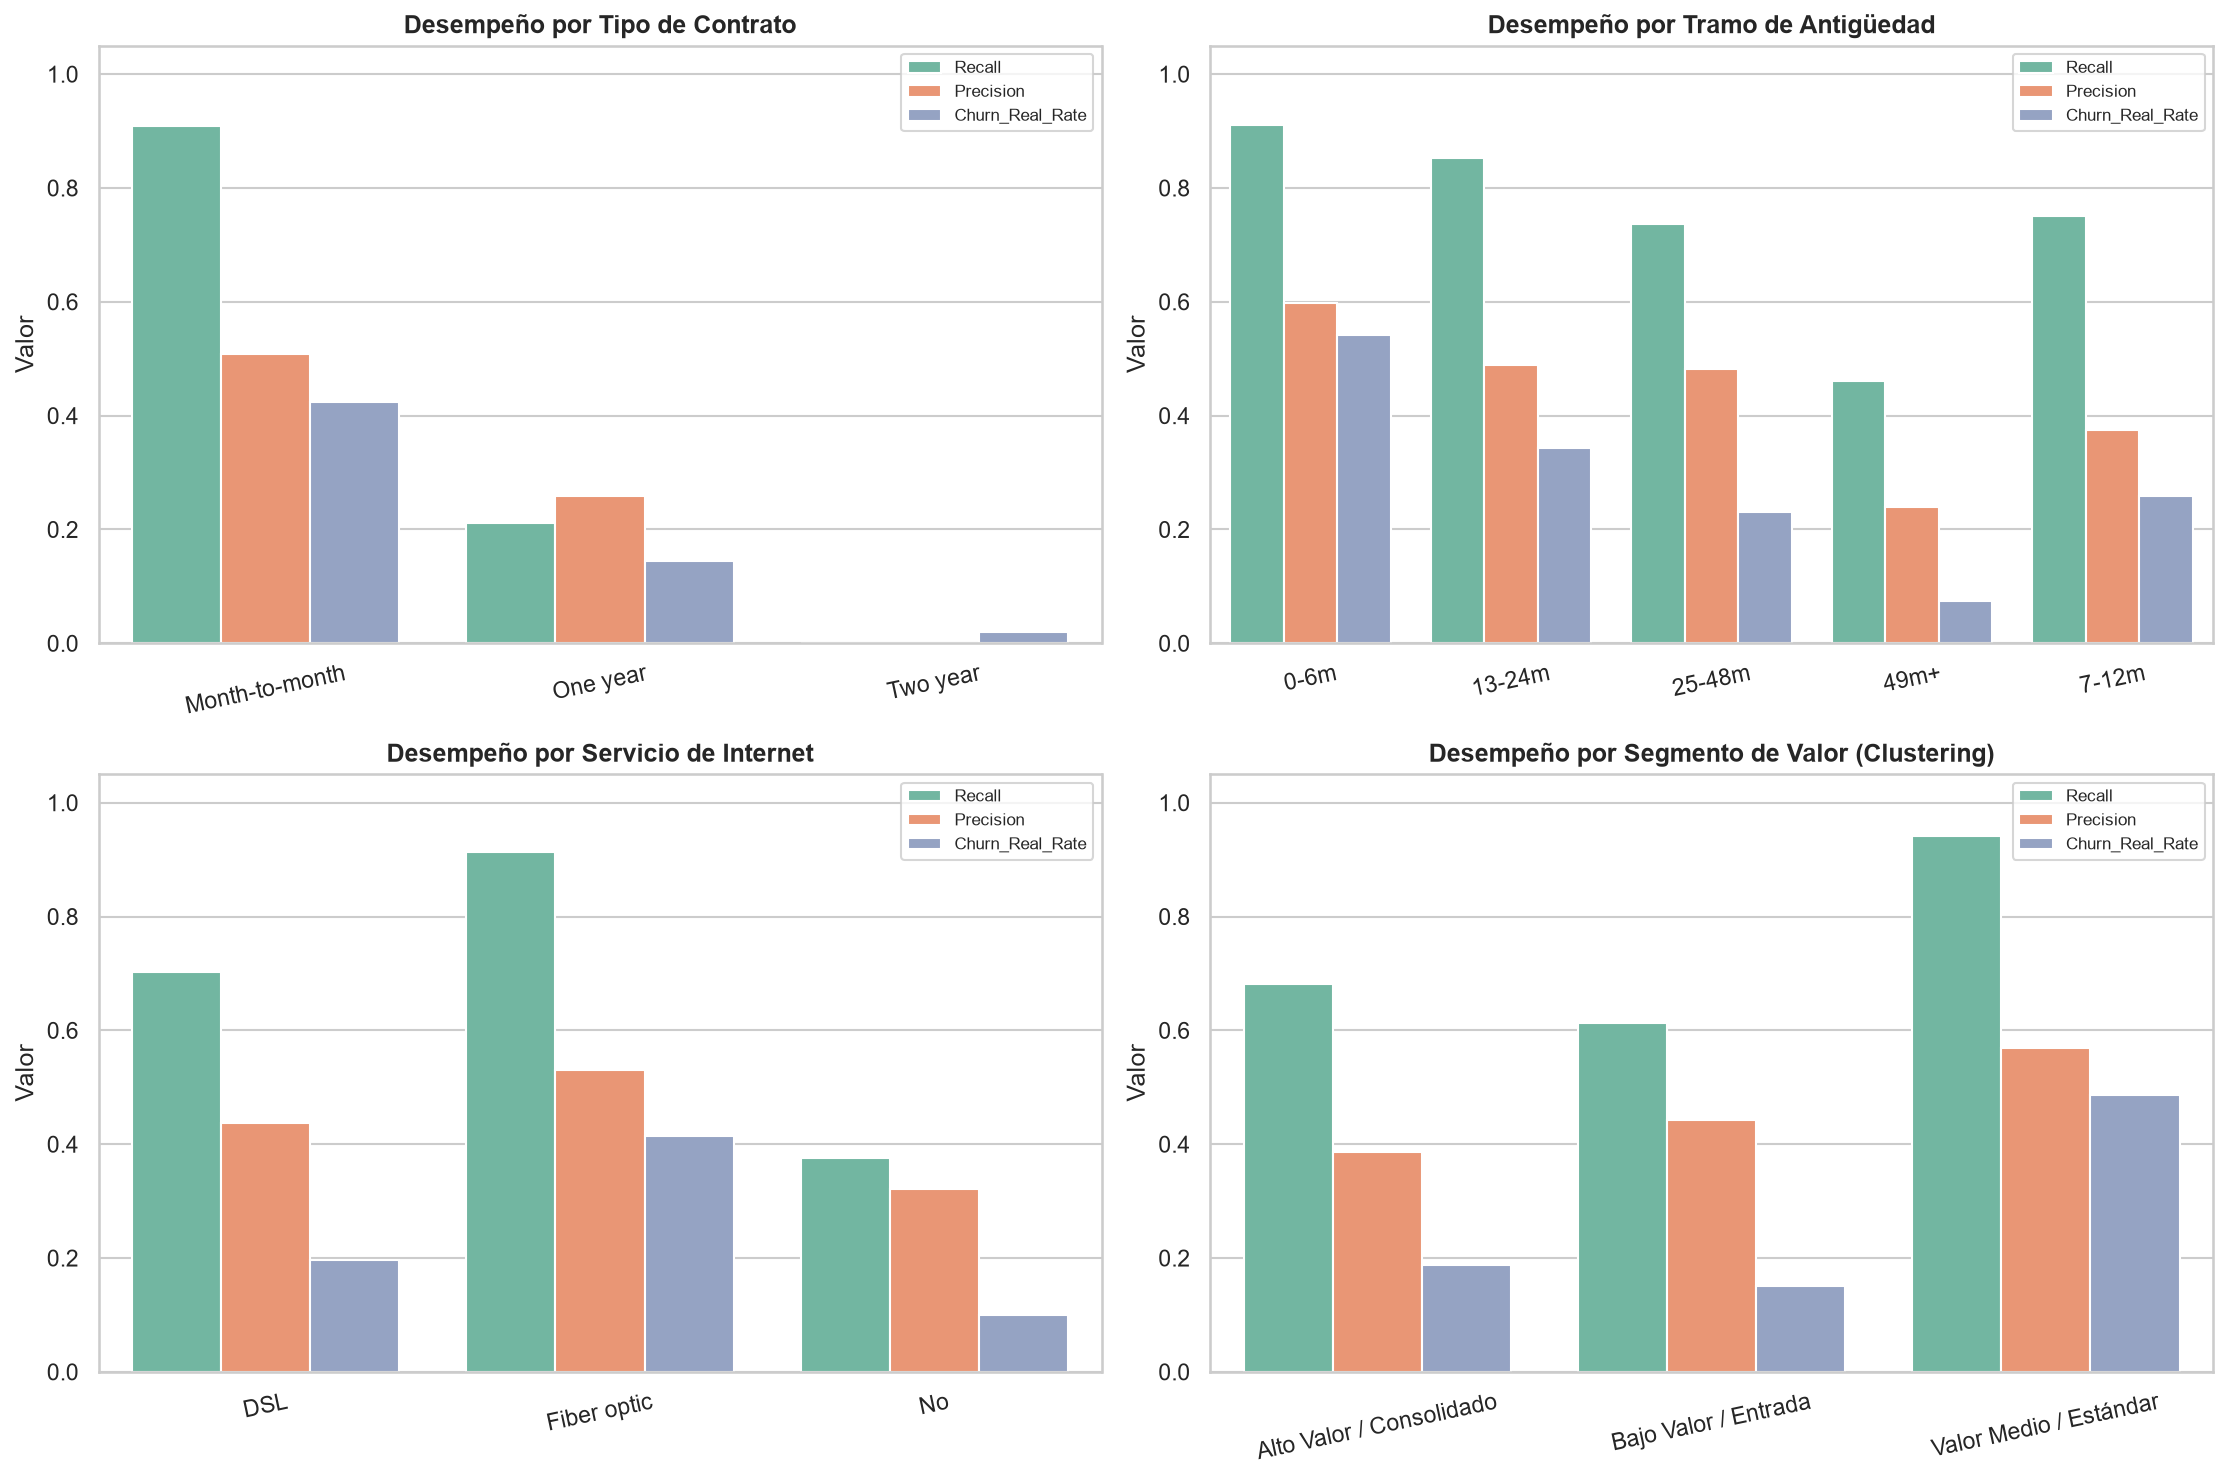

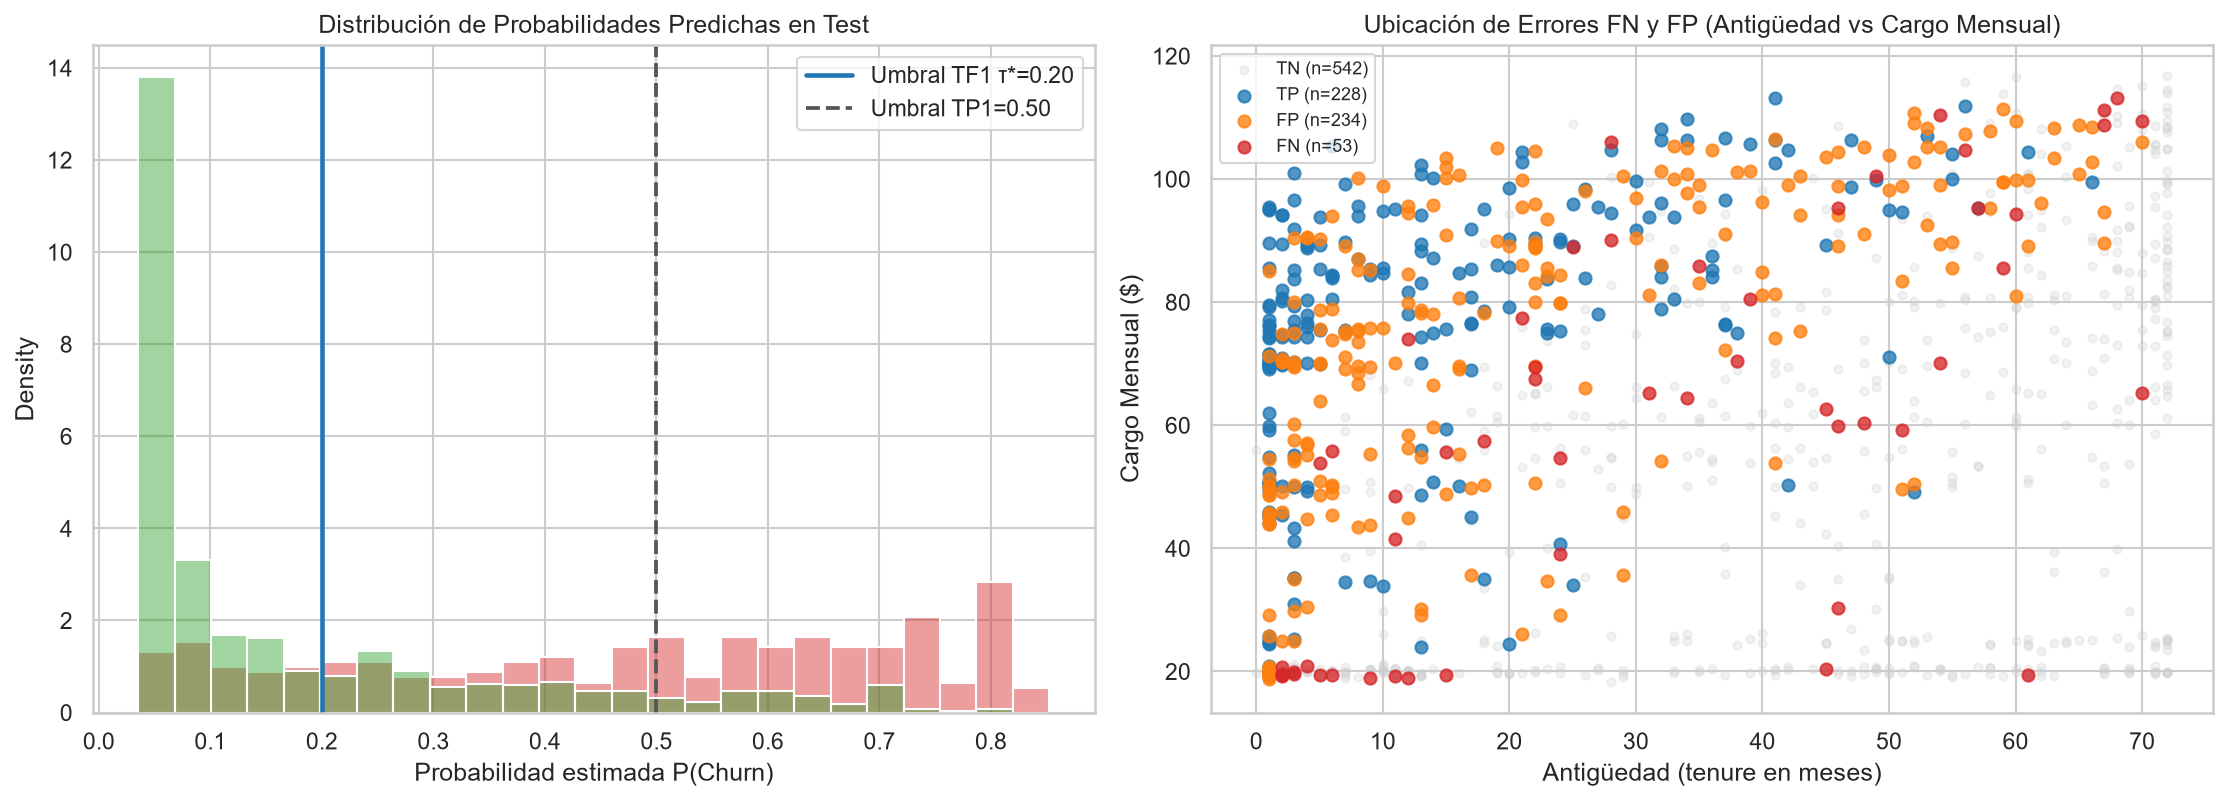

In [4]:
df_quad = pd.read_csv(REPORTS_DIR / "error_analysis_cuadrantes_tf1.csv")
display(df_quad.round(4))

df_seg = pd.read_csv(REPORTS_DIR / "error_analysis_segmentos_tf1.csv")
display(df_seg.round(4))

display(Image(filename=str(FIGURES_TF1_DIR / "error_analysis_segmentos.png")))
display(Image(filename=str(FIGURES_TF1_DIR / "error_analysis_distribucion_proba.png")))

In [5]:
df_cases = pd.read_csv(REPORTS_DIR / "error_analysis_casos_tf1.csv")
display(df_cases[["Tipo_Error", "customerID", "y_proba", "Cluster_Label", "Contract", "tenure", "MonthlyCharges", "Evidencia_Observada", "Hipotesis_Explicativa"]])

,Tipo_Error,customerID,y_proba,Cluster_Label,Contract,tenure,MonthlyCharges,Evidencia_Observada,Hipotesis_Explicativa
0,FN,5271-YNWVR,0.0673,Alto Valor / Consolidado,Two year,68,113.15,"Contract=Two year, tenure=68m, MonthlyCharges=...",Hipótesis: el contrato de largo plazo y/o alta...
1,FN,2659-VXMWZ,0.1689,Alto Valor / Consolidado,One year,67,111.30,"Contract=One year, tenure=67m, MonthlyCharges=...",Hipótesis: el contrato de largo plazo y/o alta...
2,FN,3870-MQAMG,0.1953,Alto Valor / Consolidado,One year,54,110.35,"Contract=One year, tenure=54m, MonthlyCharges=...",Hipótesis: el contrato de largo plazo y/o alta...
3,FN,0748-RDGGM,0.1270,Alto Valor / Consolidado,One year,70,109.50,"Contract=One year, tenure=70m, MonthlyCharges=...",Hipótesis: el contrato de largo plazo y/o alta...
4,FN,1150-WFARN,0.0764,Alto Valor / Consolidado,Two year,67,108.75,"Contract=Two year, tenure=67m, MonthlyCharges=...",Hipótesis: el contrato de largo plazo y/o alta...
5,FP,1628-BIZYP,0.8144,Valor Medio / Estándar,Month-to-month,1,85.00,"Contract=Month-to-month, tenure=1m, MonthlyCha...",Hipótesis: reúne múltiples factores estadístic...
6,FP,3878-AVSOQ,0.8080,Valor Medio / Estándar,Month-to-month,1,71.25,"Contract=Month-to-month, tenure=1m, MonthlyCha...",Hipótesis: reúne múltiples factores estadístic...
7,FP,0916-QOFDP,0.7613,Valor Medio / Estándar,Month-to-month,14,95.80,"Contract=Month-to-month, tenure=14m, MonthlyCh...",Hipótesis: reúne múltiples factores estadístic...
8,FP,2754-SDJRD,0.7478,Valor Medio / Estándar,Month-to-month,8,100.15,"Contract=Month-to-month, tenure=8m, MonthlyCha...",Hipótesis: reúne múltiples factores estadístic...
9,FP,9094-AZPHK,0.7412,Valor Medio / Estándar,Month-to-month,15,100.15,"Contract=Month-to-month, tenure=15m, MonthlyCh...",Hipótesis: reúne múltiples factores estadístic...


**Conclusiones del Análisis de Errores (Evidencia vs. Hipótesis):**
1. **Evidencia en Falsos Negativos (`n = 53`):** Mientras los Verdaderos Positivos tienen antigüedad media de `14.0` meses y `96.9%` contrato mes a mes, los Falsos Negativos presentan antigüedad media de **`31.0` meses** y **`58.5%` contratos de 1 o 2 años** (`26` FN en `One year`, `Recall = 21.2%`; `5` FN en `Two year`, `Recall = 0%`).
2. **Fortaleza en segmentos críticos:** En el segmento más vulnerable (`Month-to-month`: `Recall = 90.9%`; `Fiber optic`: `Recall = 91.3%`; `0-6m`: `Recall = 91.1%`; Cluster Valor Medio: `Recall = 94.1%`), la cobertura es muy alta.
3. **Hipótesis explicativa:** Los clientes consolidados que igual abandonan responden probablemente a eventos no observados en el corte transversal del dataset (averías técnicas recientes, alza tarifaria puntual o vencimiento de contrato anual sin renovación automática).
4. **Evidencia en Falsos Positivos (`n = 234`):** El `91.5%` son `Month-to-month`, `63.2%` usan Fibra Óptica y `72.6%` no tienen soporte técnico; son indistinguibles en las variables disponibles de quienes sí se fugaron, lo cual confirma la existencia de un techo informativo en los atributos estáticos de IBM Telco.